In [1]:
import tensorflow as tf 
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt 

In [2]:
## loading the data directory --
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "..\\Data\\animals\\",
    batch_size=32, 
    image_size=(224,224),
    shuffle=True,
    color_mode="rgb" 
)

Found 5400 files belonging to 90 classes.


In [3]:
## class_names
class_names = dataset.class_names
class_names

['antelope',
 'badger',
 'bat',
 'bear',
 'bee',
 'beetle',
 'bison',
 'boar',
 'butterfly',
 'cat',
 'caterpillar',
 'chimpanzee',
 'cockroach',
 'cow',
 'coyote',
 'crab',
 'crow',
 'deer',
 'dog',
 'dolphin',
 'donkey',
 'dragonfly',
 'duck',
 'eagle',
 'elephant',
 'flamingo',
 'fly',
 'fox',
 'goat',
 'goldfish',
 'goose',
 'gorilla',
 'grasshopper',
 'hamster',
 'hare',
 'hedgehog',
 'hippopotamus',
 'hornbill',
 'horse',
 'hummingbird',
 'hyena',
 'jellyfish',
 'kangaroo',
 'koala',
 'ladybugs',
 'leopard',
 'lion',
 'lizard',
 'lobster',
 'mosquito',
 'moth',
 'mouse',
 'octopus',
 'okapi',
 'orangutan',
 'otter',
 'owl',
 'ox',
 'oyster',
 'panda',
 'parrot',
 'pelecaniformes',
 'penguin',
 'pig',
 'pigeon',
 'porcupine',
 'possum',
 'raccoon',
 'rat',
 'reindeer',
 'rhinoceros',
 'sandpiper',
 'seahorse',
 'seal',
 'shark',
 'sheep',
 'snake',
 'sparrow',
 'squid',
 'squirrel',
 'starfish',
 'swan',
 'tiger',
 'turkey',
 'turtle',
 'whale',
 'wolf',
 'wombat',
 'woodpecker',


In [4]:
len(dataset) ## 32 images per batch ==> 169*32=5408

169

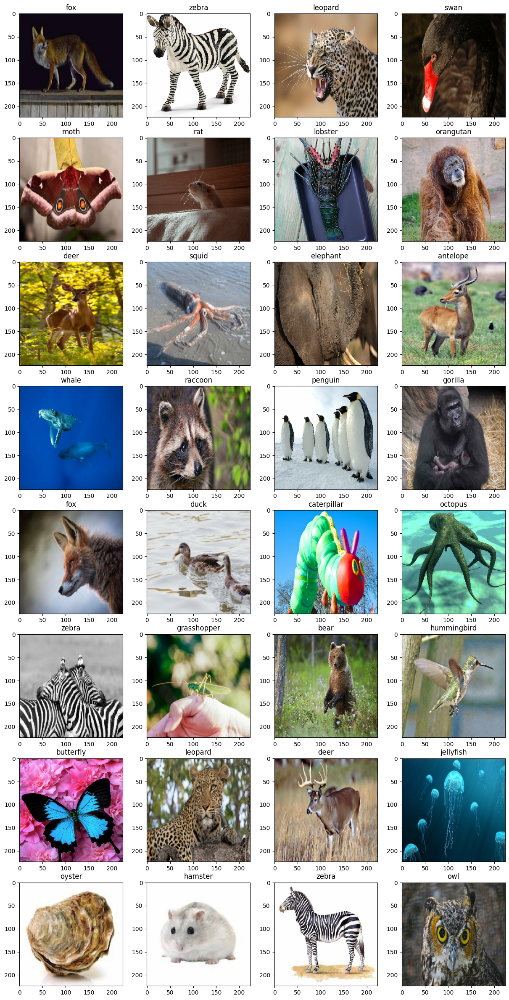

In [5]:
plt.figure(figsize=(15,30))
for image_batch,label_batch in dataset.take(1):
    for i in range(32):
        plt.subplot(8,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])

# Splitting the Dataset into Train(80%),Test(10%) and Validation(10%)

In [6]:
def get_dataset_partitions(ds,train_split=0.8,val_split=0.1,test_split=0.1,shuffle=True,shuffle_size=10000):

    ds_size = len(dataset)

    if shuffle:
        ds = ds.shuffle(shuffle_size,seed=12)
    train_size = int(train_split*ds_size)
    val_size = int(val_split*ds_size) 

    train_ds = ds.take(train_size)
    validation_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    
    return train_ds,validation_ds,test_ds

In [7]:
train_ds,val_ds,test_ds = get_dataset_partitions(dataset)

In [8]:
len(train_ds),len(test_ds),len(val_ds)

(135, 18, 16)

## Resizing and Rescaling

In [9]:
from tensorflow.keras.applications.vgg16 import preprocess_input

In [10]:
## Applying VGG16 preprocessing 

def process(image,label):
    image = tf.cast(image,tf.float32)
    image = preprocess_input(image)
    return image,label

In [11]:
## Applying process function to the dataset
train_ds = train_ds.map(process).cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.map(process).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.map(process).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [12]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(224,224),
])

In [13]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(height_factor=(0.2, 0.3)),
    layers.RandomZoom(height_factor=(-0.3,-0.2)),
])

## Transfer Learing (Pretrained model )

In [14]:
## Loading VGG16 model 

conv_base = tf.keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(224,224,3)
)

### Fine Tuning

In [15]:
## Freezing the Convolution layers and Training the Dense Layers and Some Convolution layers with custom data
conv_base.trainable = True

set_trainable = False

for layer in conv_base.layers: 
    if layer.name == 'block5_conv1': 
        set_trainable = True 
    if set_trainable: 
        layer.trainable = True 
    else: layer.trainable = False 
for layer in conv_base.layers: 
    print(layer.name,layer.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [16]:
model = models.Sequential([
    resize_and_rescale, 
    data_augmentation,
    conv_base, 
    layers.GlobalAveragePooling2D(),
    layers.Dense(256,activation='relu'), ## Relu activation function
    layers.Dropout(0.3),  ## Using Dropout to avoid overfitting
    layers.Dense(len(class_names),activation='softmax') ## As the dataset is a multiclass, So using 'Softmax'
])

In [17]:
model.build(input_shape=(None, 224, 224, 3)) #force building the model

In [18]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 90)                  │          23,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,869,146 (56.72 MB)

 Trainable params: 7,233,882 (27.60 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [19]:
model.compile(
    optimizer=tf.optimizers.RMSprop(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
## compiling the model at 0.0001 learning rate 

In [20]:
from tensorflow.keras.callbacks import EarlyStopping

In [21]:
early_stopping_callbacks = EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True) ##Applying EarlyStopping to avoid Overfitting

In [22]:
history = model.fit(train_ds,validation_data=val_ds,epochs=25,callbacks=[early_stopping_callbacks]) ## 25 epochs

Epoch 1/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 408s 3s/step - accuracy: 0.0232 - loss: 4.5402 - val_accuracy: 0.0273 - val_loss: 4.4064
Epoch 2/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 388s 3s/step - accuracy: 0.0427 - loss: 4.3200 - val_accuracy: 0.0781 - val_loss: 4.0476
Epoch 3/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 384s 3s/step - accuracy: 0.1078 - loss: 4.0219 - val_accuracy: 0.1816 - val_loss: 3.5956
Epoch 4/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 386s 3s/step - accuracy: 0.1695 - loss: 3.6665 - val_accuracy: 0.2520 - val_loss: 3.2220
Epoch 5/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 385s 3s/step - accuracy: 0.2303 - loss: 3.3142 - val_accuracy: 0.3242 - val_loss: 2.7943
Epoch 6/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 378s 3s/step - accuracy: 0.3008 - loss: 2.9517 - val_accuracy: 0.4121 - val_loss: 2.3398
Epoch 7/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 395s 3s/step - accuracy: 0.3525 - loss: 2.6145 - val_accuracy: 0.5391 - val_loss: 1.9623
Epoch 8/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 364s 3s/step - accuracy: 0.4265 - loss: 2.2971 - val_accu

In [23]:
scores = model.evaluate(test_ds) ## Evaluating the model on test_data

18/18 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.8559 - loss: 0.6677


## Predictions on Test Data

first image prediction : 
actual label: lobster
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
predicted label: lobster


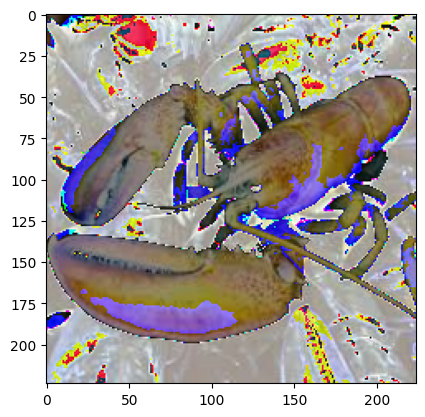

In [31]:
for image_batch,labels_batch in test_ds.take(1):
    first_image = image_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0].numpy()

    print("first image prediction : ")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])

    batch_prediction = model.predict(image_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])

In [26]:
def predict(model,img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array,0)

    predicions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predicions[0])]
    confidence = round(100*(np.max(predicions[0])),2)
    return predicted_class,confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 712ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

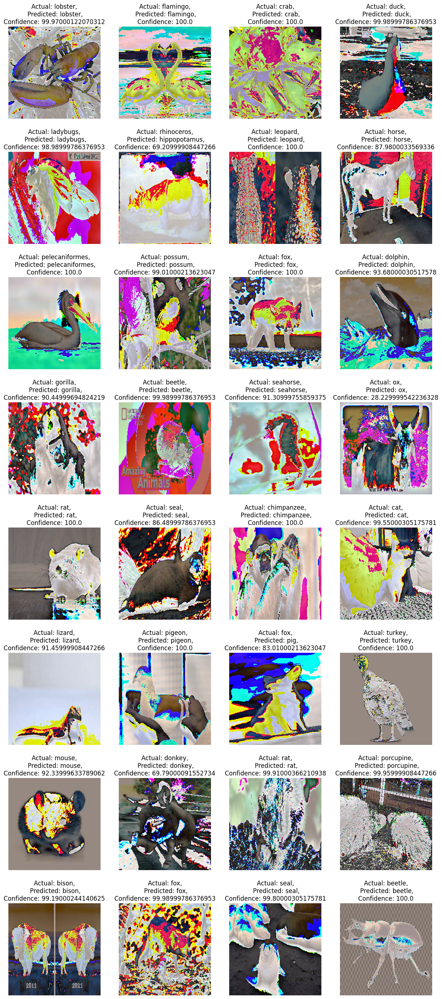

In [27]:
plt.figure(figsize=(15,35))
for images,labels in test_ds.take(1):
    for i in range(32):
        plt.subplot(8,4,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class,confidence = predict(model,images[i].numpy())
        actual_class = class_names[labels[i]]
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class},\nConfidence: {confidence}")
        plt.axis("off")

## Predicting on single image 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
Predicted class: hummingbird


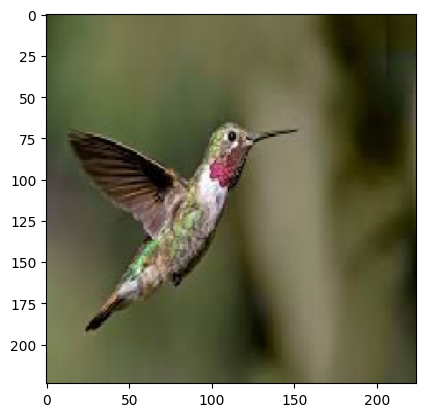

In [28]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "D:/Artificial Intelligence/Deep Learning/Project2/Animal_Classifier/Data/animals/hummingbird/02d0664b65.jpg"

# Load and preprocess image
img = image.load_img(img_path, target_size=(224,224))
x = image.img_to_array(img)
plt.imshow(x.astype("uint8"))
x = np.expand_dims(x, axis=0)

# Applying VGG16 preprocessing
from tensorflow.keras.applications.vgg16 import preprocess_input
x = preprocess_input(x)

# Prediction
preds = model.predict(x)
pred_class = np.argmax(preds[0])
print("Predicted class:", class_names[pred_class])

In [29]:
# ## saving the model
# model_version = 2
# model.save(f"../models/classifier_{model_version}_acc_85.h5")